BASELINE RESULTS (20 sessions)
Mean delta      = 0.337
Median delta    = 0.387
Std delta       = 0.305
Min delta       = -0.230
Max delta       = 0.862
Delta > 0       : 17/20 (85%)
Delta > 0.5     : 7/20 (35%)
Delta < 0       : 3/20
Converged       : 17/20
Not converged   : 3/20
Mean conv step  : 1572k
Min conv step   : 920k
Max conv step   : 1930k


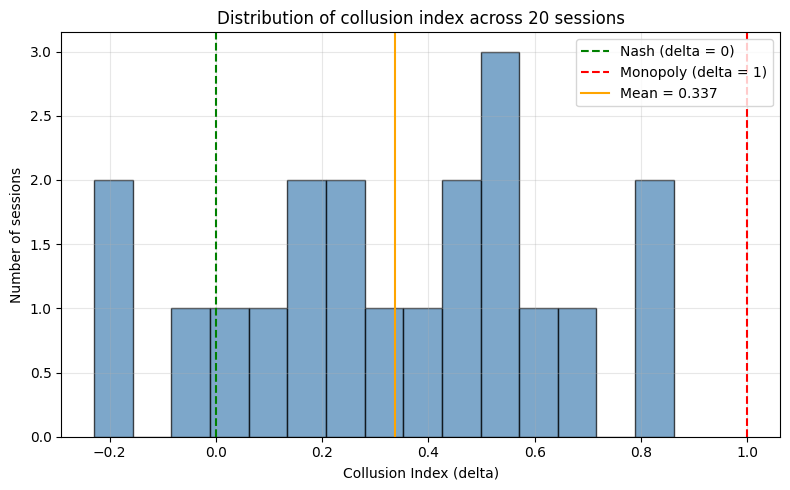

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

#loading the results
df = pd.read_csv("sac_summary.csv")

#getting delta and converged at columns
deltas = df["delta"].values
converged_at = df["converged_at"].values

#summary statistics
print("BASELINE RESULTS (%d sessions)" % len(deltas))
print("Mean delta      = %.3f" % np.mean(deltas))
print("Median delta    = %.3f" % np.median(deltas))
print("Std delta       = %.3f" % np.std(deltas))
print("Min delta       = %.3f" % np.min(deltas))
print("Max delta       = %.3f" % np.max(deltas))
print("Delta > 0       : %d/%d (%.0f%%)" % (np.sum(deltas > 0), len(deltas), 100 * np.mean(deltas > 0)))
print("Delta > 0.5     : %d/%d (%.0f%%)" % (np.sum(deltas > 0.5), len(deltas), 100 * np.mean(deltas > 0.5)))
print("Delta < 0       : %d/%d" % (np.sum(deltas < 0), len(deltas)))

#convergence statistics
converged = converged_at[converged_at > 0]
not_converged = np.sum(converged_at < 0)

print("Converged       : %d/%d" % (len(converged), len(deltas)))
print("Not converged   : %d/%d" % (not_converged, len(deltas)))
if len(converged) > 0:
    print("Mean conv step  : %dk" % (np.mean(converged) / 1000))
    print("Min conv step   : %dk" % (np.min(converged) / 1000))
    print("Max conv step   : %dk" % (np.max(converged) / 1000))

#plotting histogram
fig, ax = plt.subplots(figsize=(8, 5))
ax.hist(deltas, bins=15, edgecolor="black", alpha=0.7, color="steelblue")
ax.axvline(0, color="green", ls="--", lw=1.5, label="Nash (delta = 0)")
ax.axvline(1, color="red", ls="--", lw=1.5, label="Monopoly (delta = 1)")
ax.axvline(np.mean(deltas), color="orange", ls="-", lw=1.5,
           label="Mean = %.3f" % np.mean(deltas))
ax.set_xlabel("Collusion Index (delta)")
ax.set_ylabel("Number of sessions")
ax.set_title("Distribution of collusion index across 20 sessions")
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

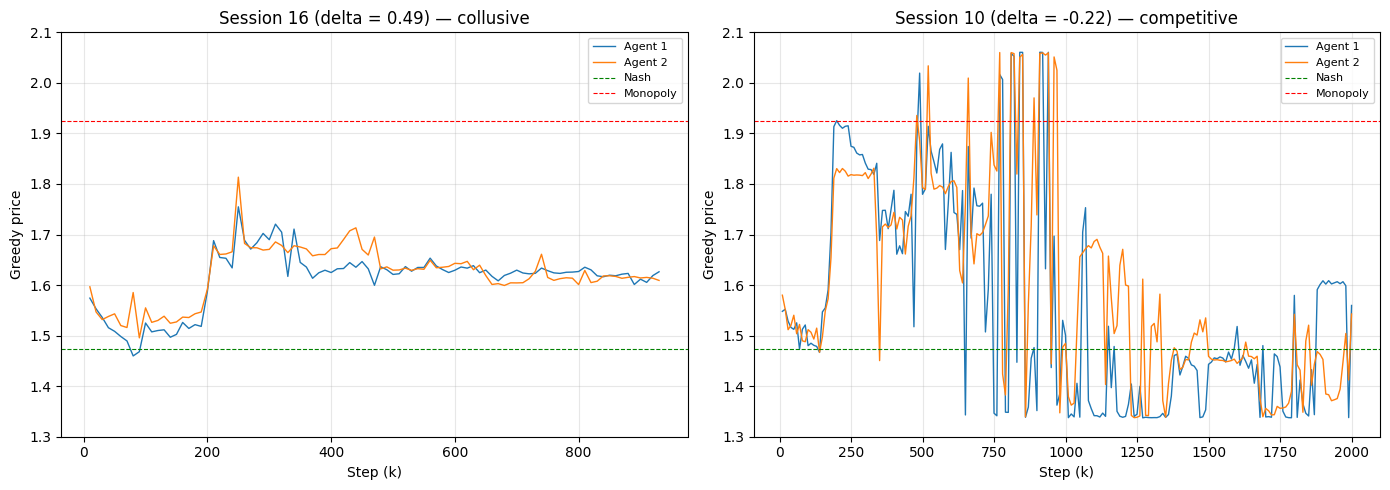

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

#hardcoding nash and monopoly prices
P_NASH = 1.4729
P_MONO = 1.9250

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

#reading session 16 and plotting
logs = pd.read_csv("sac_session_16_logs.csv")
ax = axes[0]
ax.plot(logs["step"] / 1000, logs["greedy_p1"], lw=1, label="Agent 1")
ax.plot(logs["step"] / 1000, logs["greedy_p2"], lw=1, label="Agent 2")
ax.axhline(P_NASH, color="green", ls="--", lw=0.8, label="Nash")
ax.axhline(P_MONO, color="red", ls="--", lw=0.8, label="Monopoly")
ax.set_xlabel("Step (k)")
ax.set_ylabel("Greedy price")
ax.set_title("Session 16 (delta = 0.49) — collusive")
ax.legend(fontsize=8)
ax.set_ylim(1.3, 2.1)
ax.grid(True, alpha=0.3)

#reading session 10 and plotting
logs = pd.read_csv("sac_session_10_logs.csv")
ax = axes[1]
ax.plot(logs["step"] / 1000, logs["greedy_p1"], lw=1, label="Agent 1")
ax.plot(logs["step"] / 1000, logs["greedy_p2"], lw=1, label="Agent 2")
ax.axhline(P_NASH, color="green", ls="--", lw=0.8, label="Nash")
ax.axhline(P_MONO, color="red", ls="--", lw=0.8, label="Monopoly")
ax.set_xlabel("Step (k)")
ax.set_ylabel("Greedy price")
ax.set_title("Session 10 (delta = -0.22) — competitive")
ax.legend(fontsize=8)
ax.set_ylim(1.3, 2.1)
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

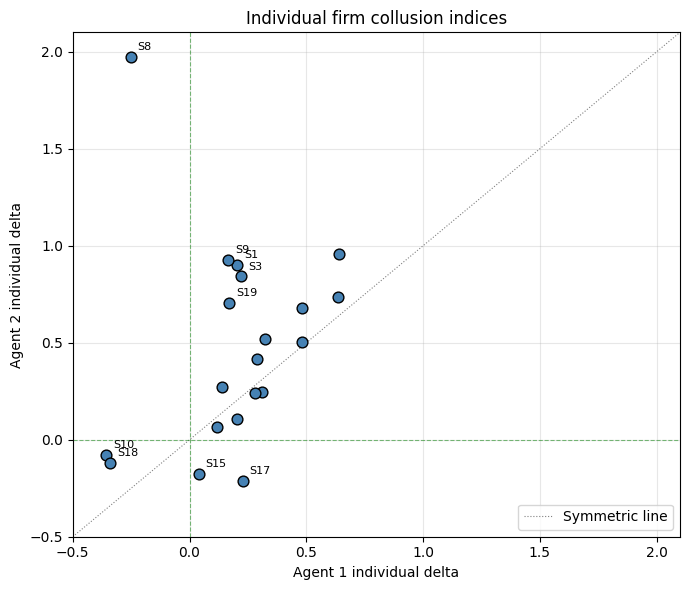

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

#hardcoding nash and monopoly prices
PI_NASH = 0.2229
PI_MONO = 0.3375

#calculating the delta's for each agent
d1 = (df["avg_profit_1"].values - PI_NASH) / (PI_MONO - PI_NASH)
d2 = (df["avg_profit_2"].values - PI_NASH) / (PI_MONO - PI_NASH)

fig, ax = plt.subplots(figsize=(7, 6))
ax.scatter(d1, d2, s=60, color="steelblue", edgecolors="black", zorder=3)

#labeling interesting sessions
for i in range(20):
    if abs(d1[i] - d2[i]) > 0.5 or d1[i] < 0 or d2[i] < 0:
        ax.annotate("S%d" % i, (d1[i], d2[i]), fontsize=8,
                    xytext=(5, 5), textcoords="offset points")
#plotting
ax.plot([-0.5, 2.1], [-0.5, 2.1], ls=":", color="gray", lw=0.8, label="Symmetric line")
ax.axhline(0, color="green", ls="--", lw=0.8, alpha=0.5)
ax.axvline(0, color="green", ls="--", lw=0.8, alpha=0.5)
ax.set_xlabel("Agent 1 individual delta")
ax.set_ylabel("Agent 2 individual delta")
ax.set_title("Individual firm collusion indices")
ax.legend()
ax.grid(True, alpha=0.3)
ax.set_xlim(-0.5, 2.1)
ax.set_ylim(-0.5, 2.1)
plt.tight_layout()
plt.show()

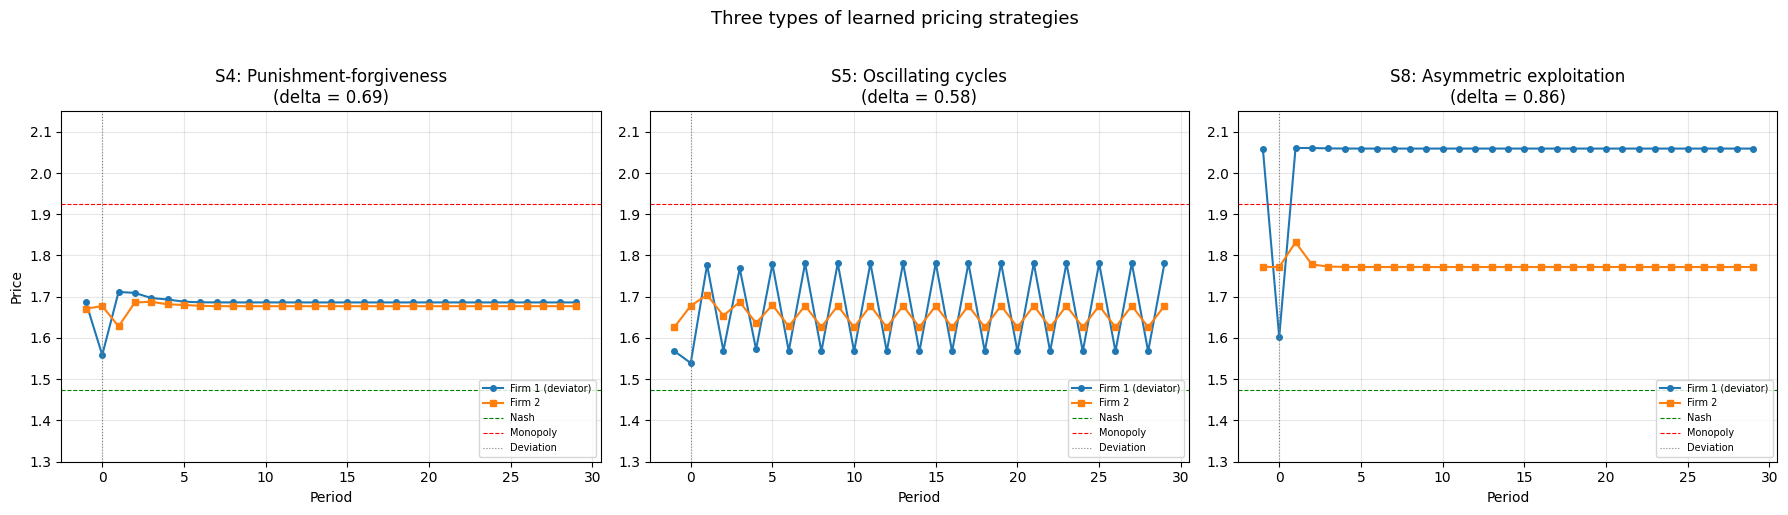

In [ ]:
import numpy as np
import torch
import torch.nn.functional as F
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import minimize_scalar

#setting up environment parameters
C = 1.0
A = 2.0
A0 = 0.0
MU = 0.25
P_NASH = 1.4729
P_MONO = 1.9250
SPREAD = P_MONO - P_NASH
P_MIN = P_NASH - 0.3 * SPREAD
P_MAX = P_MONO + 0.3 * SPREAD

def demand(pi, pj):
    num = np.exp((A - pi) / MU)
    return num / (num + np.exp((A - pj) / MU) + np.exp(A0 / MU))

def profit(pi, pj):
    return (pi - C) * demand(pi, pj)

def normalise_price(p):
    return (p - P_MIN) / (P_MAX - P_MIN)

def unnormalise_action(a):
    return P_MIN + (a + 1) * 0.5 * (P_MAX - P_MIN)

#doing a feedforward to get a greedy price
def get_greedy_price(actor_params, own_p, opp_p):
    s = torch.tensor([normalise_price(own_p), normalise_price(opp_p)],
                     dtype=torch.float32).unsqueeze(0)
    with torch.no_grad():
        h = F.relu(s @ actor_params["l1_w"].T + actor_params["l1_b"])
        h = F.relu(h @ actor_params["l2_w"].T + actor_params["l2_b"])
        mu = h @ actor_params["mu_w"].T + actor_params["mu_b"]
        a = torch.tanh(mu).squeeze(-1).item()
    return unnormalise_action(a)

#punishment test
def run_punishment(actor1, actor2, p1_star, p2_star):
    #getting best response of firm 1
    best = minimize_scalar(lambda p: -profit(p, p2_star),
                           bounds=(P_MIN, P_MAX), method="bounded")
    #setting the deviation
    p1_dev = best.x

    traj = [(p1_star, p2_star)]
    p1 = p1_star
    p2 = p2_star

    for step in range(30):
        if step == 0:
            new_p1 = p1_dev
        else:
          #feedforward to get response
            new_p1 = get_greedy_price(actor1, p1, p2)
        new_p2 = get_greedy_price(actor2, p2, p1)
        p1 = new_p1
        p2 = new_p2
        traj.append((p1, p2))

    return np.array(traj)

#setting up plotting
sessions = [4, 5, 8]
titles = [
    "S4: Punishment-forgiveness",
    "S5: Oscillating cycles",
    "S8: Asymmetric exploitation"
]


fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for idx in range(3):
    si = sessions[idx]
    delta = df["delta"].iloc[si]

    # load saved agents
    checkpoint = torch.load("sac_agents_session_%d.pt" % si,
                            map_location="cpu")
    actor1 = checkpoint["agent1_actor"]
    actor2 = checkpoint["agent2_actor"]

    # get final greedy prices as starting point
    logs = pd.read_csv("sac_session_%d_logs.csv" % si)
    p1_star = logs.iloc[-1]["greedy_p1"]
    p2_star = logs.iloc[-1]["greedy_p2"]

    # run test
    traj = run_punishment(actor1, actor2, p1_star, p2_star)
    steps = np.arange(-1, len(traj) - 1)

    # plot
    ax = axes[idx]
    ax.plot(steps, traj[:, 0], "o-", ms=4, label="Firm 1 (deviator)")
    ax.plot(steps, traj[:, 1], "s-", ms=4, label="Firm 2")
    ax.axhline(P_NASH, color="green", ls="--", lw=0.8, label="Nash")
    ax.axhline(P_MONO, color="red", ls="--", lw=0.8, label="Monopoly")
    ax.axvline(0, color="gray", ls=":", lw=0.8, label="Deviation")
    ax.set_title("%s\n(delta = %.2f)" % (titles[idx], delta))
    ax.set_xlabel("Period")
    ax.set_ylim(1.3, 2.15)
    if idx == 0:
        ax.set_ylabel("Price")
    ax.legend(fontsize=7, loc="lower right")
    ax.grid(True, alpha=0.3)

plt.suptitle("Three types of learned pricing strategies", fontsize=13, y=1.02)
plt.tight_layout()
plt.show()

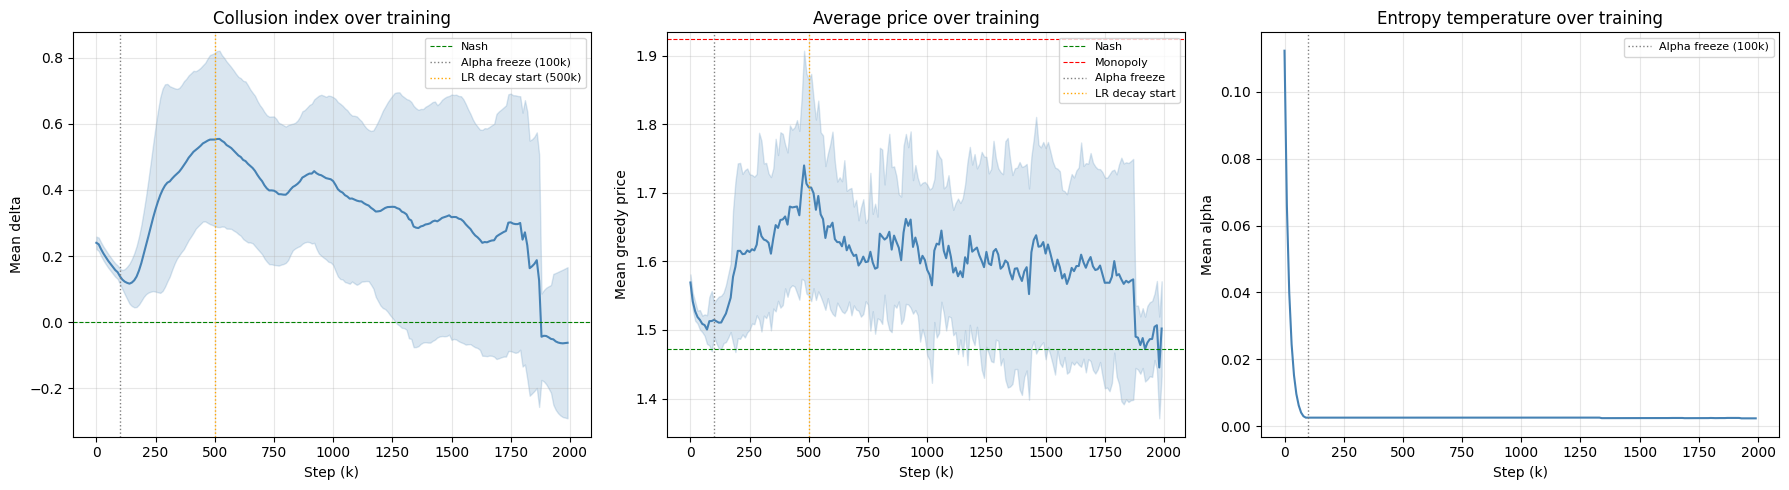

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

#loading all the session logs
logs = []
for i in range(20):
    df = pd.read_csv("sac_session_%d_logs.csv" % i)
    logs.append(df)

#finding the max length to build arrays
max_rows = max(len(df) for df in logs)

all_deltas = np.full((20, max_rows), np.nan)
all_prices = np.full((20, max_rows), np.nan)
all_alphas = np.full((20, max_rows), np.nan)

#appending all sessions
for i in range(20):
    df = logs[i]
    n = len(df)
    all_deltas[i, :n] = df["delta"].values
    all_prices[i, :n] = (df["greedy_p1"].values + df["greedy_p2"].values) / 2
    all_alphas[i, :n] = (df["alpha_1"].values + df["alpha_2"].values) / 2

#each row is 10k steps
steps_k = np.arange(max_rows) * 10

#computing means and stds
mean_delta = np.nanmean(all_deltas, axis=0)
std_delta = np.nanstd(all_deltas, axis=0)
mean_price = np.nanmean(all_prices, axis=0)
std_price = np.nanstd(all_prices, axis=0)
mean_alpha = np.nanmean(all_alphas, axis=0)

#hardcoding nash and monopoly
P_NASH = 1.4729
P_MONO = 1.9250

#plotting
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

#mean delta
ax = axes[0]
ax.plot(steps_k, mean_delta, color="steelblue", lw=1.5)
ax.fill_between(steps_k, mean_delta - std_delta, mean_delta + std_delta,
                alpha=0.2, color="steelblue")
ax.axhline(0, color="green", ls="--", lw=0.8, label="Nash")
ax.axvline(100, color="gray", ls=":", lw=1, label="Alpha freeze (100k)")
ax.axvline(500, color="orange", ls=":", lw=1, label="LR decay start (500k)")
ax.set_xlabel("Step (k)")
ax.set_ylabel("Mean delta")
ax.set_title("Collusion index over training")
ax.legend(fontsize=8)
ax.grid(True, alpha=0.3)

#mean greedy price
ax = axes[1]
ax.plot(steps_k, mean_price, color="steelblue", lw=1.5)
ax.fill_between(steps_k, mean_price - std_price, mean_price + std_price,
                alpha=0.2, color="steelblue")
ax.axhline(P_NASH, color="green", ls="--", lw=0.8, label="Nash")
ax.axhline(P_MONO, color="red", ls="--", lw=0.8, label="Monopoly")
ax.axvline(100, color="gray", ls=":", lw=1, label="Alpha freeze")
ax.axvline(500, color="orange", ls=":", lw=1, label="LR decay start")
ax.set_xlabel("Step (k)")
ax.set_ylabel("Mean greedy price")
ax.set_title("Average price over training")
ax.legend(fontsize=8)
ax.grid(True, alpha=0.3)

#mean alpha
ax = axes[2]
ax.plot(steps_k, mean_alpha, color="steelblue", lw=1.5)
ax.axvline(100, color="gray", ls=":", lw=1, label="Alpha freeze (100k)")
ax.set_xlabel("Step (k)")
ax.set_ylabel("Mean alpha")
ax.set_title("Entropy temperature over training")
ax.legend(fontsize=8)
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

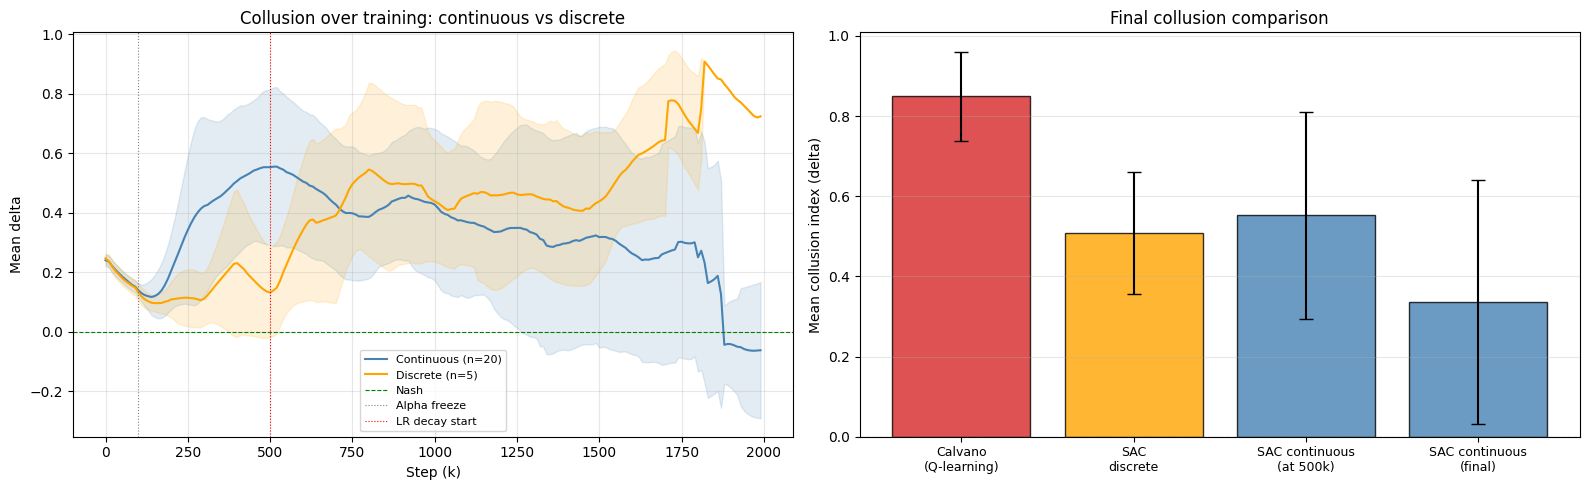

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

#loading the continuous summary dataset
summary_cont = pd.read_csv("sac_summary.csv")
deltas_cont_final = summary_cont["delta"].values

#reading all 20 sessions
cont_logs = []
for i in range(20):
    df = pd.read_csv("sac_session_%d_logs.csv" % i)
    cont_logs.append(df)

#loading discrete
disc_dir = "/content/Discrete Action Set/"
summary_disc = pd.read_csv(disc_dir + "sac_summary.csv")
deltas_disc_final = summary_disc["delta"].values

disc_logs = []
n_disc = len(deltas_disc_final)
for i in range(n_disc):
    df = pd.read_csv(disc_dir + "sac_session_%d_logs.csv" % i)
    disc_logs.append(df)

#building the delta arrays
max_rows = max(max(len(df) for df in cont_logs),
               max(len(df) for df in disc_logs))

cont_deltas = np.full((20, max_rows), np.nan)
disc_deltas = np.full((n_disc, max_rows), np.nan)

#appending
for i in range(20):
    n = len(cont_logs[i])
    cont_deltas[i, :n] = cont_logs[i]["delta"].values

for i in range(n_disc):
    n = len(disc_logs[i])
    disc_deltas[i, :n] = disc_logs[i]["delta"].values

steps_k = np.arange(max_rows) * 10

#calculating mean and stds
mean_cont = np.nanmean(cont_deltas, axis=0)
std_cont = np.nanstd(cont_deltas, axis=0)
mean_disc = np.nanmean(disc_deltas, axis=0)
std_disc = np.nanstd(disc_deltas, axis=0)

#getting the delta at 500k
delta_500k_cont = []
for i in range(20):
    row = cont_logs[i][cont_logs[i]["step"] >= 500000]
    if len(row) > 0:
        delta_500k_cont.append(row.iloc[0]["delta"])
    else:
        delta_500k_cont.append(np.nan)

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

#learning curve
ax = axes[0]
ax.plot(steps_k, mean_cont, color="steelblue", lw=1.5, label="Continuous (n=20)")
ax.fill_between(steps_k, mean_cont - std_cont, mean_cont + std_cont,
                alpha=0.15, color="steelblue")
ax.plot(steps_k, mean_disc, color="orange", lw=1.5, label="Discrete (n=5)")
ax.fill_between(steps_k, mean_disc - std_disc, mean_disc + std_disc,
                alpha=0.15, color="orange")
ax.axhline(0, color="green", ls="--", lw=0.8, label="Nash")
ax.axvline(100, color="gray", ls=":", lw=0.8, label="Alpha freeze")
ax.axvline(500, color="red", ls=":", lw=0.8, label="LR decay start")
ax.set_xlabel("Step (k)")
ax.set_ylabel("Mean delta")
ax.set_title("Collusion over training: continuous vs discrete")
ax.legend(fontsize=8)
ax.grid(True, alpha=0.3)

#barchart with hardcoded calvano
ax = axes[1]
labels = ["Calvano\n(Q-learning)", "SAC\ndiscrete", "SAC continuous\n(at 500k)", "SAC continuous\n(final)"]
means = [0.849,
         np.mean(deltas_disc_final),
         np.nanmean(delta_500k_cont),
         np.mean(deltas_cont_final)]
stds = [0.112,
        np.std(deltas_disc_final),
        np.nanstd(delta_500k_cont),
        np.std(deltas_cont_final)]
colors = ["#d62728", "orange", "steelblue", "steelblue"]

bars = ax.bar(range(4), means, yerr=stds, capsize=5, color=colors,
              edgecolor="black", alpha=0.8)
ax.set_xticks(range(4))
ax.set_xticklabels(labels, fontsize=9)
ax.set_ylabel("Mean collusion index (delta)")
ax.set_title("Final collusion comparison")
ax.axhline(0, color="green", ls="--", lw=0.8)
ax.grid(True, alpha=0.3, axis="y")

plt.tight_layout()
plt.show()